V. Network analysis with miRDB

1.) Import packages


In [1]:
#import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
#import GEOparse

2.) Load data

In [2]:
# Expression data
mirna_expr = pd.read_csv("data/pfc_mirna_expression.csv")
mrna_expr = pd.read_csv("data/pfc_mrna_gene_expression.csv")

# Sample metadata and miRNA annotation
mirna_meta = pd.read_csv("data/pfc_mirna_sample_info.csv")
mrna_meta = pd.read_csv("data/pfc_mrna_sample_info.csv")
mirna_annotation = pd.read_csv("data/pfc_mirna_annotation.csv")

# Networks

mirdb_network = pd.read_csv(
    "data/pfc_network_mirdb_high_confidence.csv"
)

print("Files loaded successfully.")



Files loaded successfully.


3.) Match miRNA and mRNA data

In [3]:
# Keep only metadata for mRNA samples present in the cleaned matrix
mrna_sample_ids = mrna_expr.columns[1:]

mrna_meta_retained = mrna_meta[
    mrna_meta["GSM"].isin(mrna_sample_ids)
].copy()

print("mRNA expression samples:", len(mrna_sample_ids))
print("Matched metadata rows:", len(mrna_meta_retained))

mRNA expression samples: 58
Matched metadata rows: 58


In [4]:
# standardize species names
mirna_meta["Species_key"] = (
    mirna_meta["Species"]
    .str.lower()
    .replace({"rhesus macaque": "macaque"})
)

mrna_meta_retained["Species_key"] = (
    mrna_meta_retained["Species"]
    .str.lower()
    .replace({"rhesus macaque": "macaque"})
)

# Biological ages used for matching
mirna_meta["match_age_days"] = mirna_meta["Original_age_days"]
mrna_meta_retained["match_age_days"] = mrna_meta_retained["Age_days"]

display(mirna_meta.head())
display(mrna_meta_retained.head())

,Sample,Code,Region,Age_days,Original_age_days,Log2_Age,Species,GSM,N_matches,Species_key,match_age_days
0,Hsa_PFC_3days,Hsa,PFC,3,2,1.584963,human,GSM725664,1,human,2
1,Hsa_PFC_5days,Hsa,PFC,5,4,2.321928,human,GSM725669,1,human,4
2,Hsa_PFC_95days,Hsa,PFC,95,94,6.569856,human,GSM725662,1,human,94
3,Hsa_PFC_788days,Hsa,PFC,788,787,9.622052,human,GSM725629,1,human,787
4,Hsa_PFC_1631days,Hsa,PFC,1631,1630,10.671541,human,GSM725641,1,human,1630


,GSM,Title,Source,Characteristics,Description,Species,Age_days,Log2_Age,Species_key,match_age_days
0,GSM559183,Human - superior frontal gyrus - 14309 days old,Dissected Human post-mortem superior frontal g...,"['age: 14309 days', 'gender: m', 'tissue: supe...","[""The dataset contains two prenatal individual...",Human,14309,13.804736,human,14309
1,GSM559184,Human - superior frontal gyrus - 1630 days old,Dissected Human post-mortem superior frontal g...,"['age: 1630 days', 'gender: f', 'tissue: super...","[""The dataset contains two prenatal individual...",Human,1630,10.671541,human,1630
2,GSM559185,Human - superior frontal gyrus - 19457 days old,Dissected Human post-mortem superior frontal g...,"['age: 19457 days', 'gender: m', 'tissue: supe...","[""The dataset contains two prenatal individual...",Human,19457,14.248076,human,19457
3,GSM559187,Human - superior frontal gyrus - 204 days old,Dissected Human post-mortem superior frontal g...,"['age: 204 days', 'gender: m', 'tissue: superi...","[""The dataset contains two prenatal individual...",Human,204,7.679480,human,204
4,GSM559188,Human - superior frontal gyrus - 21204 days old,Dissected Human post-mortem superior frontal g...,"['age: 21204 days', 'gender: m', 'tissue: supe...","[""The dataset contains two prenatal individual...",Human,21204,14.372117,human,21204


4.) Create exact species and age matches

In [5]:
sample_matches = mirna_meta.merge(
    mrna_meta_retained,
    on=["Species_key", "match_age_days"],
    how="inner",
    suffixes=("_mirna", "_mrna"),
    validate="one_to_one"
)

sample_matches = sample_matches[
    [
        "Species_key",
        "match_age_days",
        "Sample",
        "GSM_mirna",
        "GSM_mrna",
    ]
].rename(
    columns={
        "Species_key": "Species",
        "Sample": "miRNA_sample",
        "GSM_mirna": "miRNA_GSM",
        "GSM_mrna": "mRNA_GSM",
    }
)

sample_matches = sample_matches.sort_values(
    ["Species", "match_age_days"]
).reset_index(drop=True)

display(sample_matches)

,Species,match_age_days,miRNA_sample,miRNA_GSM,mRNA_GSM
0,chimpanzee,0,Ptr_PFC_1days,"GSM725625, GSM725626",GSM559239
1,chimpanzee,1,Ptr_PFC_2days,"GSM725631, GSM725632",GSM559242
2,chimpanzee,8,Ptr_PFC_9days,GSM725637,GSM559250
3,chimpanzee,39,Ptr_PFC_40days,"GSM725635, GSM725636",GSM559245
4,chimpanzee,525,Ptr_PFC_526days,"GSM725623, GSM725624",GSM559249
5,chimpanzee,2313,Ptr_PFC_2314days,GSM725639,GSM559243
6,chimpanzee,4361,Ptr_PFC_4362days,GSM725659,GSM559246
7,chimpanzee,4415,Ptr_PFC_4416days,GSM725660,GSM559247
8,chimpanzee,12784,Ptr_PFC_12785days,GSM725685,GSM559240
9,chimpanzee,16131,Ptr_PFC_16132days,"GSM725677, GSM725678",GSM559241


In [6]:
#check matched cohort

match_counts = (
    sample_matches.groupby("Species")
    .size()
    .rename("N_matches")
    .reset_index()
)

display(match_counts)
print("Total matched profiles:", len(sample_matches))

,Species,N_matches
0,chimpanzee,10
1,human,7
2,macaque,7


Total matched profiles: 24


In [7]:
#Display individuals in miRNA data that are unmatched

unmatched_mirna = (
    mirna_meta.merge(
        sample_matches[
            ["miRNA_sample", "mRNA_GSM"]
        ],
        left_on="Sample",
        right_on="miRNA_sample",
        how="left",
    )
    .loc[lambda df: df["mRNA_GSM"].isna()]
    [
        [
            "Sample",
            "Species",
            "Original_age_days",
            "GSM",
        ]
    ]
    .reset_index(drop=True)
)

display(unmatched_mirna)

,Sample,Species,Original_age_days,GSM
0,Hsa_PFC_3days,human,2,GSM725664
1,Ptr_PFC_46days,chimpanzee,45,GSM725633
2,Mml_PFC_1488days,macaque,1487,GSM725646


5.) Align and standardize expression matrices

In [8]:
sample_matches["profile_id"] = (
    sample_matches["Species"]
    + "_"
    + sample_matches["match_age_days"].astype(str)
)

sample_matches[
    ["profile_id", "miRNA_sample", "mRNA_GSM"]
]

,profile_id,miRNA_sample,mRNA_GSM
0,chimpanzee_0,Ptr_PFC_1days,GSM559239
1,chimpanzee_1,Ptr_PFC_2days,GSM559242
2,chimpanzee_8,Ptr_PFC_9days,GSM559250
3,chimpanzee_39,Ptr_PFC_40days,GSM559245
4,chimpanzee_525,Ptr_PFC_526days,GSM559249
5,chimpanzee_2313,Ptr_PFC_2314days,GSM559243
6,chimpanzee_4361,Ptr_PFC_4362days,GSM559246
7,chimpanzee_4415,Ptr_PFC_4416days,GSM559247
8,chimpanzee_12784,Ptr_PFC_12785days,GSM559240
9,chimpanzee_16131,Ptr_PFC_16132days,GSM559241


In [9]:
#Align expression matrices
# miRNA: rows are miRNAs and columns are matched profiles
mirna_matched = (
    mirna_expr
    .set_index("ID_REF")
    [sample_matches["miRNA_sample"]]
    .copy()
)

# mRNA: rows are genes and columns are matched profiles
mrna_matched = (
    mrna_expr
    .set_index("Gene")
    [sample_matches["mRNA_GSM"]]
    .copy()
)

# Give corresponding miRNA and mRNA columns identical names
mirna_matched.columns = sample_matches["profile_id"]
mrna_matched.columns = sample_matches["profile_id"]

assert mirna_matched.columns.equals(mrna_matched.columns)

print("miRNA matrix:", mirna_matched.shape)
print("mRNA matrix:", mrna_matched.shape)

miRNA matrix: (198, 24)
mRNA matrix: (11667, 24)


6. Define row-wise standardization and map measured miRNA to TargetSeed 8.0

In [10]:
def zscore_rows(df):
    row_means = df.mean(axis=1)
    row_sd = df.std(axis=1, ddof=1)

    z = df.sub(row_means, axis=0).div(row_sd, axis=0)

    # Remove a feature only if it has no variation
    return z.dropna(axis=0, how="any")

In [11]:
seed_map = (
    mirna_annotation
    .drop_duplicates("miRNA_original")
    .set_index("miRNA_original")["Seed+m8"]
)

mirna_seed_mapping = pd.DataFrame(
    {
        "miRNA": mirna_matched.index,
        "Seed": seed_map.reindex(mirna_matched.index).values
    }
)

mapped_mask = mirna_seed_mapping["Seed"].notna()

print("Measured miRNAs:", len(mirna_seed_mapping))
print("Mapped miRNAs:", mapped_mask.sum())
print("Unmapped miRNAs:", (~mapped_mask).sum())

display(mirna_seed_mapping.loc[~mapped_mask])

Measured miRNAs: 198
Mapped miRNAs: 197
Unmapped miRNAs: 1


,miRNA,Seed
186,hsa-mir-886-3p,NaN


7.) Standardize the miRNAs and aggregate them by seed

In [12]:
mapped_mirnas = mirna_seed_mapping.loc[
    mapped_mask, "miRNA"
].tolist()

mirna_z = zscore_rows(
    mirna_matched.loc[mapped_mirnas]
)

# Add the seed corresponding to each standardized miRNA
mirna_z["Seed"] = seed_map.loc[mirna_z.index]

# Average standardized expression across miRNAs sharing a seed
seed_z = (
    mirna_z
    .groupby("Seed")
    .mean(numeric_only=True)
)

print("Seed-expression matrix:", seed_z.shape)

Seed-expression matrix: (157, 24)


In [13]:
#Standardize the gene-expression matrix:
gene_z = zscore_rows(mrna_matched)

print("Gene-expression matrix:", gene_z.shape)

Gene-expression matrix: (11667, 24)


8.) Load the high-confidence miRDB network

In [14]:
mirdb = (
    mirdb_network[
        ["Seed", "Gene"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

9.) Construct MiRDB network

In [15]:
mirdb = mirdb[
    mirdb["Seed"].isin(seed_z.index)
    & mirdb["Gene"].isin(gene_z.index)
].reset_index(drop=True)

network = mirdb.copy()

# Verify
print("Edges:", len(network))
print("Seed families:", network["Seed"].nunique())
print("Target genes:", network["Gene"].nunique())
print(
    "Duplicate edges:",
    network.duplicated(["Seed", "Gene"]).sum()
)

Edges: 24111
Seed families: 156
Target genes: 7039
Duplicate edges: 0


10. Calculate edge-activity scores

In [16]:
#verify column match
assert seed_z.columns.equals(gene_z.columns)

print("Profiles:", len(seed_z.columns))
print("Network edges:", len(network))

Profiles: 24
Network edges: 24111


In [17]:
#extract seed scores
seed_edge_z = seed_z.loc[
    network["Seed"]
].to_numpy()

gene_edge_z = gene_z.loc[
    network["Gene"]
].to_numpy()

#calculate difference
edge_contrast = seed_edge_z - gene_edge_z

#apply logistic transformation
edge_score_values = 1 / (1 + np.exp(-edge_contrast))

#store the result as a labeled DataFrame:
edge_index = pd.MultiIndex.from_frame(
    network[["Seed", "Gene"]]
)

edge_scores = pd.DataFrame(
    edge_score_values,
    index=edge_index,
    columns=seed_z.columns
)

edge_scores.index.names = ["Seed", "Gene"]

print("Edge-score matrix:", edge_scores.shape)
display(edge_scores.head())

#check the range
print(
    "Minimum edge score:",
    edge_scores.to_numpy().min()
)

print(
    "Maximum edge score:",
    edge_scores.to_numpy().max()
)

print(
    "Mean edge score:",
    edge_scores.to_numpy().mean()
)

Edge-score matrix: (24111, 24)


profile_id      chimpanzee_0  chimpanzee_1  chimpanzee_8  chimpanzee_39  \
Seed    Gene                                                              
AAAGCUG ABCC5       0.946563      0.925328      0.924045       0.305221   
        ABHD13      0.652215      0.963903      0.316979       0.371464   
        ACBD3       0.809776      0.943145      0.730946       0.459946   
        ACOT7       0.735733      0.760469      0.812794       0.168373   
        ACTL6A      0.875815      0.884985      0.764338       0.598669   

profile_id      chimpanzee_525  chimpanzee_2313  chimpanzee_4361  \
Seed    Gene                                                       
AAAGCUG ABCC5         0.551516         0.130622         0.694903   
        ABHD13        0.648430         0.235254         0.489625   
        ACBD3         0.704962         0.657712         0.677474   
        ACOT7         0.396292         0.109387         0.691133   
        ACTL6A        0.687709         0.439484         0.475646   

profile_id      chimpanzee_4415  chimpanzee_12784  chimpanzee_16131  ...  \
Seed    Gene                                                         ...   
AAAGCUG ABCC5          0.888634          0.095247          0.162358  ...   
        ABHD13         0.820802          0.128120          0.255220  ...   
        ACBD3          0.917648          0.461360          0.286000  ...   
        ACOT7          0.877679          0.441482          0.380352  ...   
        ACTL6A         0.890483          0.477070          0.045217  ...   

profile_id      human_9277  human_24090  human_32120  macaque_1  macaque_7  \
Seed    Gene                                                                 
AAAGCUG ABCC5     0.330339     0.342856     0.280508   0.344573   0.247447   
        ABHD13    0.448887     0.689827     0.476302   0.349808   0.260239   
        ACBD3     0.230836     0.300905     0.272259   0.145008   0.246825   
        ACOT7     0.143606     0.648732     0.699994   0.399886   0.283751   
        ACTL6A    0.301464     0.183671     0.474896   0.595270   0.492986   

profile_id      macaque_16  macaque_449  macaque_3389  macaque_8104  \
Seed    Gene                                                          
AAAGCUG ABCC5     0.696255     0.149754      0.690023      0.577460   
        ABHD13    0.193283     0.434514      0.154816      0.223704   
        ACBD3     0.091742     0.245937      0.332535      0.221658   
        ACOT7     0.361178     0.105257      0.874440      0.833915   
        ACTL6A    0.277016     0.315942      0.240426      0.177524   

profile_id      macaque_10220  
Seed    Gene                   
AAAGCUG ABCC5        0.512280  
        ABHD13       0.777472  
        ACBD3        0.225586  
        ACOT7        0.767077  
        ACTL6A       0.161489  

[5 rows x 24 columns]

Minimum edge score: 0.0029148373824116913
Maximum edge score: 0.9972053666428917
Mean edge score: 0.49966284541175227


11.) Calculate the six network features. 

In [18]:
#define normalized entropy
def normalized_entropy(values):
    values = np.asarray(values, dtype=float)

    probabilities = values / values.sum()

    entropy = -np.sum(
        probabilities * np.log(probabilities)
    )

    maximum_entropy = np.log(len(values))

    return entropy / maximum_entropy

Calculate the features for each matched profile

In [19]:
feature_rows = []

for profile_id in edge_scores.columns:

    # All edge scores for this profile
    scores = edge_scores[profile_id]

    # Mean activity of each seed family across its target edges
    family_outstrength = (
        scores
        .groupby(level="Seed")
        .mean()
    )

    # Mean activity of each target gene across its regulating seeds
    target_instrength = (
        scores
        .groupby(level="Gene")
        .mean()
    )

    feature_rows.append(
        {
            "profile_id": profile_id,

            # 1. Mean score over all network edges
            "mean_repression_score": scores.mean(),

            # 2. Fraction of edges with score >= 0.75
            "active_edge_fraction": (
                scores >= 0.75
            ).mean(),

            # 3. Dispersion of individual edge scores
            "edge_score_dispersion": scores.std(ddof=1),

            # 4. Variation in mean activity among seed families
            "family_outstrength_cv": (
                family_outstrength.std(ddof=1)
                / family_outstrength.mean()
            ),

            # 5. Variation in mean incoming activity among targets
            "target_instrength_cv": (
                target_instrength.std(ddof=1)
                / target_instrength.mean()
            ),

            # 6. Evenness of activity across seed families
            "family_outstrength_entropy": normalized_entropy(
                family_outstrength
            ),
        }
    )

network_features = pd.DataFrame(feature_rows)

#show features
network_features

,profile_id,mean_repression_score,active_edge_fraction,edge_score_dispersion,family_outstrength_cv,target_instrength_cv,family_outstrength_entropy
0,chimpanzee_0,0.483263,0.174236,0.240983,0.352123,0.429427,0.987159
1,chimpanzee_1,0.520919,0.251379,0.261841,0.388906,0.421242,0.983897
2,chimpanzee_8,0.523203,0.271536,0.275983,0.383062,0.440814,0.984650
3,chimpanzee_39,0.503938,0.204430,0.246421,0.319783,0.435966,0.989580
4,chimpanzee_525,0.440830,0.104143,0.222168,0.420430,0.430501,0.982418
5,chimpanzee_2313,0.530882,0.239268,0.247628,0.328900,0.426241,0.988770
6,chimpanzee_4361,0.496389,0.191863,0.246769,0.334907,0.426475,0.988300
7,chimpanzee_4415,0.478895,0.236075,0.288745,0.548873,0.492765,0.968270
8,chimpanzee_12784,0.460455,0.186429,0.267613,0.432764,0.476828,0.981190
9,chimpanzee_16131,0.514190,0.255858,0.272896,0.350825,0.477537,0.987544


Attach species and age information

In [20]:
network_features = network_features.merge(
    sample_matches[
        [
            "profile_id",
            "Species",
            "match_age_days",
            "miRNA_sample",
            "mRNA_GSM",
        ]
    ],
    on="profile_id",
    how="left",
    validate="one_to_one"
)

network_features["log2_age_plus_1"] = np.log2(
    network_features["match_age_days"] + 1
)
network_features.head()

,profile_id,mean_repression_score,active_edge_fraction,edge_score_dispersion,family_outstrength_cv,target_instrength_cv,family_outstrength_entropy,Species,match_age_days,miRNA_sample,mRNA_GSM,log2_age_plus_1
0,chimpanzee_0,0.483263,0.174236,0.240983,0.352123,0.429427,0.987159,chimpanzee,0,Ptr_PFC_1days,GSM559239,0.000000
1,chimpanzee_1,0.520919,0.251379,0.261841,0.388906,0.421242,0.983897,chimpanzee,1,Ptr_PFC_2days,GSM559242,1.000000
2,chimpanzee_8,0.523203,0.271536,0.275983,0.383062,0.440814,0.984650,chimpanzee,8,Ptr_PFC_9days,GSM559250,3.169925
3,chimpanzee_39,0.503938,0.204430,0.246421,0.319783,0.435966,0.989580,chimpanzee,39,Ptr_PFC_40days,GSM559245,5.321928
4,chimpanzee_525,0.440830,0.104143,0.222168,0.420430,0.430501,0.982418,chimpanzee,525,Ptr_PFC_526days,GSM559249,9.038919


Display results

In [21]:
feature_columns = [
    "mean_repression_score",
    "active_edge_fraction",
    "edge_score_dispersion",
    "family_outstrength_cv",
    "target_instrength_cv",
    "family_outstrength_entropy",
]

display(
    network_features[
        [
            "profile_id",
            "Species",
            "match_age_days",
        ]
        + feature_columns
    ].round(5)
)

,profile_id,Species,match_age_days,mean_repression_score,active_edge_fraction,edge_score_dispersion,family_outstrength_cv,target_instrength_cv,family_outstrength_entropy
0,chimpanzee_0,chimpanzee,0,0.48326,0.17424,0.24098,0.35212,0.42943,0.98716
1,chimpanzee_1,chimpanzee,1,0.52092,0.25138,0.26184,0.38891,0.42124,0.98390
2,chimpanzee_8,chimpanzee,8,0.52320,0.27154,0.27598,0.38306,0.44081,0.98465
3,chimpanzee_39,chimpanzee,39,0.50394,0.20443,0.24642,0.31978,0.43597,0.98958
4,chimpanzee_525,chimpanzee,525,0.44083,0.10414,0.22217,0.42043,0.43050,0.98242
5,chimpanzee_2313,chimpanzee,2313,0.53088,0.23927,0.24763,0.32890,0.42624,0.98877
6,chimpanzee_4361,chimpanzee,4361,0.49639,0.19186,0.24677,0.33491,0.42647,0.98830
7,chimpanzee_4415,chimpanzee,4415,0.47889,0.23607,0.28875,0.54887,0.49277,0.96827
8,chimpanzee_12784,chimpanzee,12784,0.46045,0.18643,0.26761,0.43276,0.47683,0.98119
9,chimpanzee_16131,chimpanzee,16131,0.51419,0.25586,0.27290,0.35082,0.47754,0.98754


In [22]:
#some basic checks
print("Number of profiles:", len(network_features))

print(
    "Missing feature values:",
    network_features[feature_columns]
    .isna()
    .sum()
    .sum()
)

display(
    network_features[
        feature_columns
    ].describe().T
)

Number of profiles: 24
Missing feature values: 0


,count,mean,std,min,25%,50%,75%,max
mean_repression_score,24.0,0.499663,0.024165,0.440830,0.482171,0.505879,0.517810,0.532026
active_edge_fraction,24.0,0.210455,0.041024,0.104143,0.188296,0.205321,0.236873,0.293683
edge_score_dispersion,24.0,0.253760,0.018232,0.222168,0.245061,0.252878,0.264165,0.291114
family_outstrength_cv,24.0,0.367577,0.051347,0.309406,0.335841,0.356723,0.384523,0.548873
target_instrength_cv,24.0,0.448361,0.030455,0.381992,0.430232,0.439804,0.475103,0.500226
family_outstrength_entropy,24.0,0.985682,0.004532,0.968270,0.984462,0.986680,0.988353,0.990292


12. Add life history alignment

In [23]:
life_history_scales = {
    "human": 33 / 98,
    "chimpanzee": 30 / 44,
    "macaque": 1.0,
}

network_features["life_history_scale"] = (
    network_features["Species"]
    .map(life_history_scales)
)

#check that all species were recognized
assert network_features["life_history_scale"].notna().all()

Calculate macaque equivalent ages (return to monkey)

In [24]:
network_features["macaque_equivalent_age_days"] = (
    network_features["match_age_days"]
    * network_features["life_history_scale"]
)

network_features[
    "log2_macaque_equivalent_age_plus_1"
] = np.log2(
    network_features["macaque_equivalent_age_days"] + 1
)

In [25]:
#display aligned ages
display(
    network_features[
        [
            "profile_id",
            "Species",
            "match_age_days",
            "log2_age_plus_1",
            "life_history_scale",
            "macaque_equivalent_age_days",
            "log2_macaque_equivalent_age_plus_1",
        ]
    ].sort_values(
        ["Species", "match_age_days"]
    ).round(3)
)

,profile_id,Species,match_age_days,log2_age_plus_1,life_history_scale,macaque_equivalent_age_days,log2_macaque_equivalent_age_plus_1
0,chimpanzee_0,chimpanzee,0,0.000,0.682,0.000,0.000
1,chimpanzee_1,chimpanzee,1,1.000,0.682,0.682,0.750
2,chimpanzee_8,chimpanzee,8,3.170,0.682,5.455,2.690
3,chimpanzee_39,chimpanzee,39,5.322,0.682,26.591,4.786
4,chimpanzee_525,chimpanzee,525,9.039,0.682,357.955,8.488
5,chimpanzee_2313,chimpanzee,2313,11.176,0.682,1577.045,10.624
6,chimpanzee_4361,chimpanzee,4361,12.091,0.682,2973.409,11.538
7,chimpanzee_4415,chimpanzee,4415,12.109,0.682,3010.227,11.556
8,chimpanzee_12784,chimpanzee,12784,13.642,0.682,8716.364,13.090
9,chimpanzee_16131,chimpanzee,16131,13.978,0.682,10998.409,13.425


13.) Main human-chimp statistical comparison (extract data)

In [26]:
human_chimp = network_features[
    network_features["Species"].isin(
        ["human", "chimpanzee"]
    )
].copy()

print(
    human_chimp.groupby("Species").size()
)

print("Total:", len(human_chimp))

Species
chimpanzee    10
human          7
dtype: int64
Total: 17


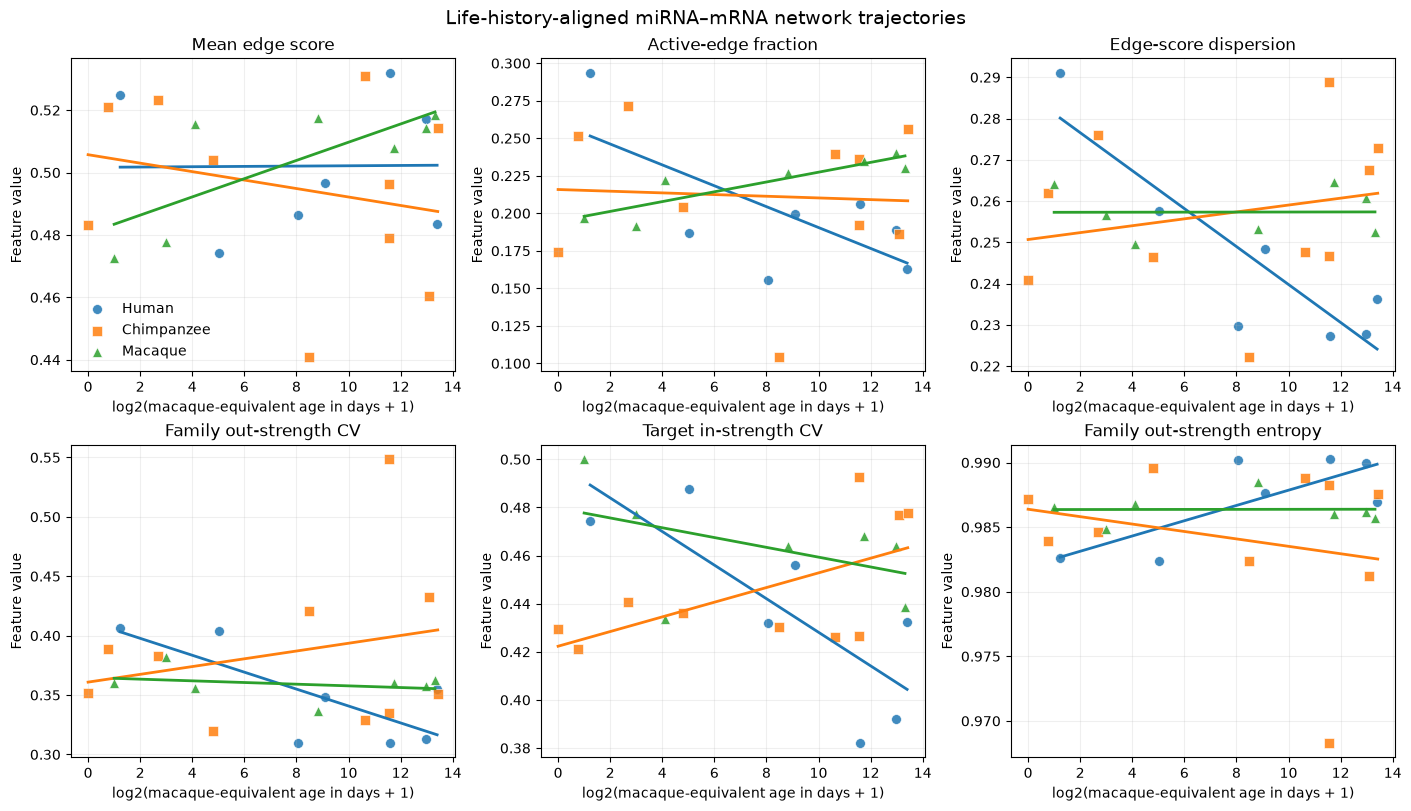

In [27]:
# Plot aligned trajectories for all three species
import matplotlib.pyplot as plt

feature_labels = {
    "mean_repression_score": "Mean edge score",
    "active_edge_fraction": "Active-edge fraction",
    "edge_score_dispersion": "Edge-score dispersion",
    "family_outstrength_cv": "Family out-strength CV",
    "target_instrength_cv": "Target in-strength CV",
    "family_outstrength_entropy": "Family out-strength entropy",
}

species_order = [
    "human",
    "chimpanzee",
    "macaque",
]

species_colors = {
    "human": "tab:blue",
    "chimpanzee": "tab:orange",
    "macaque": "tab:green",
}

species_markers = {
    "human": "o",
    "chimpanzee": "s",
    "macaque": "^",
}

x_column = "log2_macaque_equivalent_age_plus_1"

fig, axes = plt.subplots(
    2,
    3,
    figsize=(14, 8),
    constrained_layout=True
)

axes = axes.ravel()

for ax, feature in zip(axes, feature_columns):

    for species in species_order:

        subset = (
            network_features[
                network_features["Species"] == species
            ]
            .sort_values(x_column)
        )

        x = subset[x_column].to_numpy()
        y = subset[feature].to_numpy()

        ax.scatter(
            x,
            y,
            color=species_colors[species],
            marker=species_markers[species],
            label=species.capitalize(),
            s=50,
            alpha=0.85,
            edgecolor="white",
            linewidth=0.5,
        )

        # Descriptive linear trajectory for each species
        slope, intercept = np.polyfit(
            x,
            y,
            deg=1
        )

        x_line = np.linspace(
            x.min(),
            x.max(),
            100
        )

        y_line = intercept + slope * x_line

        ax.plot(
            x_line,
            y_line,
            color=species_colors[species],
            linewidth=2,
        )

    ax.set_title(feature_labels[feature])
    ax.set_xlabel(
        "log2(macaque-equivalent age in days + 1)"
    )
    ax.set_ylabel("Feature value")
    ax.grid(alpha=0.2)

axes[0].legend(
    frameon=False,
    loc="best"
)

fig.suptitle(
    "Life-history-aligned miRNA–mRNA network trajectories",
    fontsize=14
)

plt.show()

14.) Freedman Lane permutation test

In [28]:
#import package
from scipy.stats import t as student_t

In [29]:
#define the OLS fitting function:
def ols_fit(y, X):

    beta, _, _, _ = np.linalg.lstsq(
        X,
        y,
        rcond=None
    )

    fitted = X @ beta
    residuals = y - fitted

    degrees_freedom = len(y) - X.shape[1]
    residual_sum_squares = residuals @ residuals
    residual_variance = (
        residual_sum_squares / degrees_freedom
    )

    covariance = (
        residual_variance
        * np.linalg.pinv(X.T @ X)
    )

    standard_errors = np.sqrt(
        np.diag(covariance)
    )

    t_values = beta / standard_errors

    p_values = 2 * student_t.sf(
        np.abs(t_values),
        degrees_freedom
    )

    total_sum_squares = np.sum(
        (y - y.mean()) ** 2
    )

    r_squared = (
        1 - residual_sum_squares / total_sum_squares
    )

    return {
        "beta": beta,
        "fitted": fitted,
        "residuals": residuals,
        "t": t_values,
        "p": p_values,
        "r_squared": r_squared,
    }

Define Freedman Lane interaction test

In [30]:
def freedman_lane_interaction_test(
    y,
    species_indicator,
    age,
    n_permutations=5000,
    rng=None,
):

    if rng is None:
        rng = np.random.default_rng(29356)

    # Full model:
    # outcome ~ species + age + species:age
    X_full = np.column_stack(
        [
            np.ones(len(y)),
            species_indicator,
            age,
            species_indicator * age,
        ]
    )

    # Reduced null model:
    # outcome ~ species + age
    X_reduced = np.column_stack(
        [
            np.ones(len(y)),
            species_indicator,
            age,
        ]
    )

    full_fit = ols_fit(y, X_full)
    reduced_fit = ols_fit(y, X_reduced)

    observed_t = full_fit["t"][3]
    extreme_count = 0

    for _ in range(n_permutations):

        permuted_residuals = rng.permutation(
            reduced_fit["residuals"]
        )

        permuted_y = (
            reduced_fit["fitted"]
            + permuted_residuals
        )

        permuted_fit = ols_fit(
            permuted_y,
            X_full
        )

        permuted_t = permuted_fit["t"][3]

        if abs(permuted_t) >= abs(observed_t):
            extreme_count += 1

    permutation_p = (
        extreme_count + 1
    ) / (
        n_permutations + 1
    )

    return {
        "chimpanzee_slope": full_fit["beta"][2],
        "human_slope": (
            full_fit["beta"][2]
            + full_fit["beta"][3]
        ),
        "human_minus_chimpanzee_slope": (
            full_fit["beta"][3]
        ),
        "interaction_t": observed_t,
        "analytic_p": full_fit["p"][3],
        "permutation_p": permutation_p,
        "r_squared": full_fit["r_squared"],
        "n": len(y),
    }

Run test for all six features

In [31]:
rng = np.random.default_rng(29356)

species_indicator = (
    human_chimp["Species"] == "human"
).astype(int).to_numpy()

aligned_age = human_chimp[
    "log2_macaque_equivalent_age_plus_1"
].to_numpy()

test_rows = []

for feature in feature_columns:

    print("Testing:", feature)

    y = human_chimp[feature].to_numpy()

    result = freedman_lane_interaction_test(
        y=y,
        species_indicator=species_indicator,
        age=aligned_age,
        n_permutations=5000,
        rng=rng,
    )

    result["feature"] = feature
    test_rows.append(result)

permutation_results = pd.DataFrame(test_rows)

Testing: mean_repression_score
Testing: active_edge_fraction
Testing: edge_score_dispersion
Testing: family_outstrength_cv
Testing: target_instrength_cv
Testing: family_outstrength_entropy


Define Benjamini–Hochberg FDR correction

In [32]:
def benjamini_hochberg(p_values):

    p_values = np.asarray(p_values)
    number_tests = len(p_values)

    order = np.argsort(p_values)
    ranked_p = p_values[order]

    adjusted = (
        ranked_p
        * number_tests
        / np.arange(1, number_tests + 1)
    )

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.minimum(
        adjusted,
        1.0
    )

    result = np.empty(number_tests)
    result[order] = adjusted

    return result

In [33]:
#apply correction
permutation_results["fdr_bh"] = (
    benjamini_hochberg(
        permutation_results["permutation_p"]
    )
)

permutation_results = (
    permutation_results
    .sort_values("permutation_p")
    .reset_index(drop=True)
)

In [34]:
#show results
display(
    permutation_results[
        [
            "feature",
            "chimpanzee_slope",
            "human_slope",
            "human_minus_chimpanzee_slope",
            "interaction_t",
            "permutation_p",
            "fdr_bh",
            "r_squared",
            "n",
        ]
    ].round(6)
)

,feature,chimpanzee_slope,human_slope,human_minus_chimpanzee_slope,interaction_t,permutation_p,fdr_bh,r_squared,n
0,target_instrength_cv,0.003048,-0.006979,-0.010028,-3.712624,0.002200,0.013197,0.525726,17
1,edge_score_dispersion,0.000835,-0.004600,-0.005435,-2.741832,0.015197,0.045591,0.443640,17
2,family_outstrength_cv,0.003272,-0.007121,-0.010393,-1.580763,0.142372,0.242951,0.239744,17
3,family_outstrength_entropy,-0.000287,0.000591,0.000878,1.484118,0.161968,0.242951,0.211890,17
4,active_edge_fraction,-0.000561,-0.006956,-0.006396,-1.205388,0.250550,0.300660,0.181518,17
5,mean_repression_score,-0.001356,0.000050,0.001407,0.445295,0.655469,0.655469,0.058062,17


15.) Make table to identify interesting human specific regulated genes (gene_level_network_scores_mirdb.csv)

In [35]:
# Gene-level target in-strength
gene_instrength = (
    edge_scores
    .groupby(level="Gene")
    .mean()
    .T
)

gene_instrength.index.name = "profile_id"

gene_instrength_long = (
    gene_instrength
    .reset_index()
    .melt(
        id_vars="profile_id",
        var_name="Gene",
        value_name="target_instrength"
    )
)

# Gene-level incoming-edge dispersion
gene_edge_dispersion = (
    edge_scores
    .groupby(level="Gene")
    .std(ddof=1)
    .T
)

gene_edge_dispersion.index.name = "profile_id"

gene_dispersion_long = (
    gene_edge_dispersion
    .reset_index()
    .melt(
        id_vars="profile_id",
        var_name="Gene",
        value_name="incoming_edge_dispersion"
    )
)

# Combine the two gene-level features
gene_level_scores = gene_instrength_long.merge(
    gene_dispersion_long,
    on=["profile_id", "Gene"],
    how="left",
    validate="one_to_one"
)

# Number of measured seed families targeting each gene
target_degree = (
    network
    .groupby("Gene")["Seed"]
    .nunique()
    .rename("target_degree")
    .reset_index()
)

gene_level_scores = gene_level_scores.merge(
    target_degree,
    on="Gene",
    how="left",
    validate="many_to_one"
)

# Add individual metadata
gene_level_scores = gene_level_scores.merge(
    network_features[
        [
            "profile_id",
            "Species",
            "match_age_days"
        ]
    ],
    on="profile_id",
    how="left",
    validate="many_to_one"
)

# Save the single input file for the new notebook
gene_level_scores.to_csv(
    "data/gene_level_network_scores_mirdb.csv",
    index=False
)

print("Saved rows:", len(gene_level_scores))
print("Genes:", gene_level_scores["Gene"].nunique())
print("Individuals:", gene_level_scores["profile_id"].nunique())

Saved rows: 168936
Genes: 7039
Individuals: 24
